Creating and tesing the LangGraph workflow for the agent

In [13]:
from dotenv import load_dotenv
load_dotenv()

True

In [14]:
import os
import sys
import json
from pathlib import Path

# Add project root so imports like Tools.* and Resources.* work from Notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


from langchain_aws import ChatBedrockConverse
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.messages import AnyMessage

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from Tools.log_tools import log_fetch_tools

from typing import TypedDict, Annotated
from operator import add
from pydantic import BaseModel
from IPython.display import Markdown

In [15]:
llm_config = {
    'model': "us.anthropic.claude-sonnet-4-6",
    'region_name': "us-east-1"
}

In [16]:
MAX_TOOL_ROUNDS = 2  # fetch at most twice, then force a final analysis


class LogAgentState(TypedDict):
    query: str
    file_path: str
    logs: Annotated[list[dict], add]
    messages: Annotated[list[AnyMessage], add_messages]
    tool_rounds: int
    response: str


In [17]:
available_tools = log_fetch_tools
tools_by_name = {t.name: t for t in available_tools}

model = ChatBedrockConverse(**llm_config)
model_with_tools = model.bind_tools(available_tools)

In [18]:
# System Messages:

sm_fetch = '''
You are an expert log analyzer with a log-fetch tool.
Log file path: {file_path}

No logs are loaded yet. Call a fetch tool ONCE to get logs.
Rules:
- Prefer latest_logs with n=10 (n must be <= 20).
- Do not call more than one tool in this turn.
- Do not invent log contents.
'''

sm_analyze = '''
You are an expert log analyzer.
Log file path: {file_path}

Logs already loaded in state (do NOT call tools again):
{logs}

Analyze these logs, identify issues/problems, and give step-by-step recommendations.
Do not call any tools. Produce the final answer now.
'''

sm_analyze_with_query = '''
You are an expert log analyzer.
Log file path: {file_path}

Logs already loaded in state (do NOT call tools again):
{logs}

Answer the user query using these logs. Identify relevant issues and give step-by-step recommendations.
Do not call any tools. Produce the final answer now.
'''


In [19]:
def _extract_tool_round(messages_list: list) -> tuple[list[dict], bool]:
    """Pull log dicts from ToolMessages since the last AIMessage."""
    new_logs: list[dict] = []
    saw_tool = False
    i = len(messages_list) - 1
    while i >= 0:
        msg = messages_list[i]
        if getattr(msg, "type", None) == "ai":
            break
        if getattr(msg, "type", None) == "tool":
            saw_tool = True
            try:
                tool_result = json.loads(msg.content) if isinstance(msg.content, str) else msg.content
                if isinstance(tool_result, list):
                    new_logs.extend(tool_result)
            except (json.JSONDecodeError, TypeError):
                pass
        i -= 1
    return new_logs, saw_tool


def analyser(state: LogAgentState) -> dict:
    """Fetch logs via tools (limited), then produce a final analysis without tools."""
    messages_list = state.get("messages") or []
    new_logs, saw_tool = _extract_tool_round(messages_list)
    existing_logs = list(state.get("logs") or [])
    all_logs = existing_logs + new_logs
    tool_rounds = int(state.get("tool_rounds") or 0)
    query = (state.get("query") or "").strip()

    # Count every completed tool round (even empty results) to prevent loops.
    if saw_tool:
        tool_rounds += 1

    result: dict = {}
    if new_logs:
        result["logs"] = new_logs
    if saw_tool:
        result["tool_rounds"] = tool_rounds

    # Analyze once we have logs, or force-stop after the round cap.
    should_analyze = bool(all_logs) or tool_rounds >= MAX_TOOL_ROUNDS

    if should_analyze:
        if not all_logs:
            result["response"] = "No logs could be fetched from the given file path."
            result["messages"] = []
            return result

        system = sm_analyze_with_query if query else sm_analyze
        prompt_messages = [("system", system)]
        if query:
            prompt_messages.append(("user", "Query: {query}"))
        else:
            prompt_messages.append(
                ("user", "Analyze the available logs and provide issues and recommendations.")
            )

        prompt = ChatPromptTemplate.from_messages(prompt_messages)
        # Important: plain model (no tools) so the graph cannot loop on tool calls.
        chain = prompt | model
        formatted_logs = json.dumps(all_logs, indent=2, default=str)
        response = chain.invoke(
            {"file_path": state["file_path"], "query": query, "logs": formatted_logs}
        )
        result["messages"] = [response]
        result["response"] = response.content
        return result

    # First pass: ask the model to fetch logs once.
    prompt = ChatPromptTemplate.from_messages(
        [
            ("system", sm_fetch),
            (
                "user",
                (
                    f"Fetch the latest logs for this query: {query}"
                    if query
                    else "Fetch the latest 10 logs and prepare for analysis."
                ),
            ),
        ]
    )
    chain = prompt | model_with_tools
    response = chain.invoke({"file_path": state["file_path"]})

    # If the model skipped the tool, fetch latest logs deterministically once.
    if not getattr(response, "tool_calls", None):
        from Tools.log_tools import fetch_latest_logs

        fallback_logs = fetch_latest_logs.invoke(
            {"file_path": state["file_path"], "n": 10, "skip": 0}
        )
        result["logs"] = fallback_logs
        result["tool_rounds"] = tool_rounds + 1
        formatted_logs = json.dumps(fallback_logs, indent=2, default=str)
        system = sm_analyze_with_query if query else sm_analyze
        prompt_messages = [("system", system)]
        if query:
            prompt_messages.append(("user", "Query: {query}"))
        else:
            prompt_messages.append(
                ("user", "Analyze the available logs and provide issues and recommendations.")
            )
        analyze_chain = ChatPromptTemplate.from_messages(prompt_messages) | model
        final = analyze_chain.invoke(
            {"file_path": state["file_path"], "query": query, "logs": formatted_logs}
        )
        result["messages"] = [final]
        result["response"] = final.content
        return result

    result["messages"] = [response]
    return result


tool_node = ToolNode(available_tools)


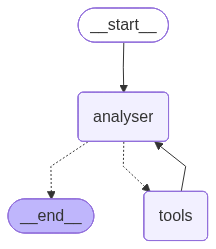

In [20]:
builder = StateGraph(LogAgentState)
builder.add_node("analyser", analyser)
builder.add_node("tools", tool_node)

builder.add_edge(START, "analyser")
builder.add_conditional_edges("analyser", tools_condition, {"tools": "tools", END: END})
builder.add_edge("tools", "analyser")

graph = builder.compile()
graph

In [21]:
# file_path = str(PROJECT_ROOT / "logs" / "pool" / "poolserver1" / "ServerManager.log")
file_path = r"C:\Data\Project\ASBG\LogAnalyser\logs\LOGS_POOL_DUMP\PoolServer1\ServerManager.log"

initial_state = {
    "query": "",  # set a question here for query mode; leave empty for latest-logs analysis
    "file_path": file_path,
    "logs": [],
    "tool_rounds": 0,
    "response": "",
}


In [22]:
# Run the workflow — logs accumulate in state["logs"], final text in state["response"]
# recursion_limit keeps LangGraph from spinning if something unexpected happens
result = graph.invoke(initial_state, config={"recursion_limit": 8})

print(f"Fetched {len(result.get('logs', []))} log entries into state")
print(f"Tool rounds: {result.get('tool_rounds', 0)}")
Markdown(result.get("response") or "(no response)")


Fetched 10 log entries into state
Tool rounds: 1


# Log Analysis Report
## File: `PoolServer1\ServerManager.log`
**Period Covered:** 2024-07-17 05:06:39 UTC – 07:34:58 UTC
**Host:** OITTOR56APCC140 | **Pool:** CADENAS_QA1_TcPoolA@8132

---

## 📊 Summary of Pool Activity

| Metric | Value |
|---|---|
| Pool Name | CADENAS_QA1_TcPoolA |
| Host | OITTOR56APCC140 |
| Port | 8132 |
| Observed Time Span | ~2 hours 28 minutes |
| TcServers Launched | 3 (tcserver00046, tcserver00047, tcserver00046) |
| TcServers Published | 5 events |
| TcServers Assigned | 2 |
| TcServers Removed/Finished | 1 (tcserver00032) |

---

## 🔴 Identified Issues

### Issue 1: TcServer Removed and Immediately Replaced (tcserver00032)
**Severity:** ⚠️ Medium

**Timeline:**
```
07:32:19.860 - tcserver00032 → REMOVED
07:32:19.894 - tcserver00032 → FINISHED   (34ms after removal)
07:32:20.050 - tcserver00047  → LAUNCHED  (156ms after finished)
07:32:23.707 - tcserver00047  → PUBLISHED (3.6 seconds after launch)
```
**Observation:**
- `tcserver00032` was removed and finished within **34 milliseconds**, indicating it was either forcefully terminated or experienced a fatal error rather than a graceful shutdown.
- The pool **immediately compensated** by launching `tcserver00047` to maintain the target pool size (Total remained at 10).
- The removal was triggered by session `DT0314593.62215.01.f05831d.08124.Mux.Svr.16250`, suggesting the server crash/removal was tied to an active multiplexer session.

---

### Issue 2: Pool Count Instability During Warm-Up Phase
**Severity:** ℹ️ Low–Medium

**Timeline of Pool Counts:**
```
05:06:39 → Total: 9,  Assigned: 2, Warm: 6, Warming: 1
05:06:39 → tcserver00046 LAUNCHED
05:06:41 → Total: 10, Assigned: 2, Warm: 7, Warming: 1
05:06:42 → Total: 10, Assigned: 2, Warm: 8            ✅ Stable
07:32:23 → Total: 10, Assigned: 2, Warm: 8            ✅ Stable (after replacement)
```
**Observation:**
- At `05:06:39`, the pool was in a **transitional/warming state** (Total=9, Warming=1), meaning it had not yet reached its target capacity.
- Two servers (tcserver00045 and tcserver00046) were still warming up simultaneously, indicating the pool was recovering from a prior reduction in capacity.
- Stability was achieved at `05:06:42` with **Total=10, Warm=8**.

---

### Issue 3: Low Warm Server Buffer Relative to Total Pool Size
**Severity:** ℹ️ Low

**Observation:**
- Final stable state: **Total=10, Assigned=2, Warm=8**
- Only 8 out of 10 servers are "warm" and available — a reasonable ratio, but note that only **2 additional assignments** would exhaust the available warm pool if no new servers are spun up quickly enough.
- With `tcserver00039` assigned at `07:24:37` and `tcserver00040` assigned at `07:34:58` (only ~10 minutes apart), the assignment rate could spike and reduce the warm buffer rapidly.

---

### Issue 4: Assigned Count Remains Constant at 2 — Potential Stale Sessions
**Severity:** ℹ️ Low–Medium

**Observation:**
- Throughout the **entire observed period (2h 28min)**, the `Assigned` count never changes from **2**.
- Sessions `c07441b~TD0374503.SharedSession` and `f05831d~DT0314593.SharedSession` appear to hold long-lived assignments.
- Long-held SharedSession assignments can be a sign of:
  - Sessions that are not being released properly.
  - Long-running or stalled user operations.
  - Potential **session/resource leak**.

---

## ✅ Step-by-Step Recommendations

### Step 1: Investigate the Removal of `tcserver00032`
1. Locate the syslog file associated with `tcserver00032` (pattern: `tcserver.exe<hash>.syslog`) on host `OITTOR56APCC140`.
2. Review the syslog for crash dumps, unhandled exceptions, memory errors, or forced termination signals.
3. Check the multiplexer session log for `DT0314593.62215.01.f05831d.08124.Mux.Svr.16250` to determine if the client triggered an abnormal disconnect.
4. Determine if `tcserver00032` was removed due to a **client-side error**, **server-side crash**, or **pool management policy** (e.g., idle timeout or max lifetime exceeded).

---

### Step 2: Validate Pool Recovery Behavior
1. Confirm that the pool target size is correctly configured at **10 servers**.
2. Verify that the auto-replacement behavior (launching `tcserver00047` within 156ms of `tcserver00032` finishing) is working as expected and is not masking a recurring crash pattern.
3. Review historical logs to check **how frequently** TcServers are being removed/finished unexpectedly — one incident may be acceptable, but a pattern would indicate a systemic problem.

---

### Step 3: Investigate the Warm-Up Incident at ~05:06 UTC
1. Review logs **prior to 05:06:39** to understand why the pool was at Total=9 with a server still warming — this suggests the pool was recently reduced or a server was lost before the log window begins.
2. Determine if a scheduled restart, deployment, or crash caused the pool to drop below target capacity.

---

### Step 4: Review and Monitor SharedSession Lifetimes
1. Audit the two long-held SharedSessions:
   - `c07441b~TD0374503.SharedSession` (assigned at 07:24:37)
   - `f05831d~DT0314593.SharedSession` (assigned at 07:34:58)
2. Set up **session timeout policies** if not already configured to automatically release idle SharedSessions.
3. Monitor if these sessions are eventually released or if they persist indefinitely, which could point to a **resource leak**.

---

### Step 5: Increase Warm Buffer or Pool Size if Needed
1. If assignment rates increase, the current warm buffer of 8 servers may not be sufficient.
2. Consider **increasing the pool's minimum warm server count** or **total pool size** to prevent users from experiencing delays while new servers warm up.
3. Implement **proactive scaling alerts** when `Warm` drops below a defined threshold (e.g., below 6).

---

### Step 6: Set Up Alerting for Abnormal Server Removals
1. Configure monitoring/alerting to trigger when a `removed` + `finished` sequence occurs within a very short time window (e.g., < 100ms), as this typically indicates a non-graceful termination.
2. Integrate log monitoring tools (e.g., ELK Stack, Splunk, or Grafana Loki) to parse `ServerManager.log` for these patterns automatically.

---

## 🔑 Key Takeaways

| # | Finding | Priority |
|---|---|---|
| 1 | `tcserver00032` removed/finished abnormally (34ms gap) | 🔴 High |
| 2 | Pool was under capacity (Total=9) at start of log | 🟡 Medium |
| 3 | Assigned count stuck at 2 for 2h+ — possible stale sessions | 🟡 Medium |
| 4 | Warm buffer could deplete quickly under higher load | 🟢 Low |
| 5 | Auto-recovery appears functional but needs monitoring | 🟢 Low |

In [25]:
with open(r'../Results/WorkflowNotebook.md', 'w', encoding='utf-8') as f:
    f.write(result.get("response"))